### 🛠️ Corrective RAG (CRAG) with Groq + HuggingFace
1. **Retrieve** docs from the vector store
2. **Grade** every doc for relevance (in parallel, strict yes/no)
3. **Decide** (CRAG-style):
   - all relevant → **Correct** → generate
   - some relevant → **Ambiguous** → keep good docs + web search
   - none relevant → **Incorrect** → web search only
4. **Re-write query** for web search (the user's original question is kept for the answer)
5. **Generate** a grounded answer with source tags

In [13]:
import os
from typing import List
from dotenv import load_dotenv
from pydantic import BaseModel, Field

from langchain.chat_models import init_chat_model
from langchain_core.documents import Document                    # langchain.schema ki jagah
from langchain_huggingface import HuggingFaceEmbeddings          # OpenAIEmbeddings ki jagah
from langchain_community.document_loaders import TextLoader
from langchain_community.vectorstores import FAISS               # langchain.vectorstores ki jagah
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import StateGraph, START, END


In [14]:
from dotenv import find_dotenv

# .env sits in the repo root, one level above this notebook
load_dotenv(find_dotenv(usecwd=True), override=True)

# .env stores the keys in lowercase; ChatGroq, huggingface_hub and Tavily read the uppercase names
os.environ["GROQ_API_KEY"]   = os.getenv("GROQ_API_KEY") or os.getenv("groq_api", "")
os.environ["HF_TOKEN"]       = os.getenv("HF_TOKEN") or os.getenv("hf_token", "")
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY") or os.getenv("tavily_api", "")

# Removes the WebBaseLoader "USER_AGENT environment variable not set" warning
os.environ.setdefault("USER_AGENT", "rag-learning-notebook/1.0")

assert os.environ["GROQ_API_KEY"], "groq_api / GROQ_API_KEY missing in .env"
assert os.environ["TAVILY_API_KEY"], "tavily_api / TAVILY_API_KEY missing in .env"
print("Keys loaded: Groq", bool(os.environ["GROQ_API_KEY"]), "| Tavily", bool(os.environ["TAVILY_API_KEY"]))

Keys loaded: Groq True | Tavily True


In [15]:
from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings

GROQ_MODEL = "openai/gpt-oss-20b"   # if grading gives errors: "openai/gpt-oss-120b"

llm = ChatGroq(model=GROQ_MODEL, temperature=0)

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [16]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import WebBaseLoader
from langchain_community.vectorstores import FAISS

urls = [
    "https://lilianweng.github.io/posts/2023-06-23-agent/",
    "https://lilianweng.github.io/posts/2023-03-15-prompt-engineering/",
    "https://lilianweng.github.io/posts/2023-10-25-adv-attack-llm/",
]

docs_list = WebBaseLoader(urls).load()

doc_splits = RecursiveCharacterTextSplitter(
    chunk_size=1500, chunk_overlap=100   # ~ same size as 500 tokens, no tiktoken needed
).split_documents(docs_list)

vectorstore = FAISS.from_documents(doc_splits, embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 4})
print(f"Pages: {len(docs_list)} | Chunks: {len(doc_splits)}")

Pages: 3 | Chunks: 116


In [17]:
from typing import Literal
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate


class GradeDocuments(BaseModel):
    """Binary score for relevance check on retrieved documents."""
    binary_score: Literal["yes", "no"] = Field(
        description="Is the document relevant to the question? 'yes' or 'no'"
    )

# json_schema: no tool-name mistakes (remember the 'searchQuery' error)
structured_llm_grader = llm.with_structured_output(GradeDocuments, method="json_schema")

grade_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a grader assessing relevance of a retrieved document to a user question.\n"
     "If the document contains keyword(s) or semantic meaning that helps answer the question, "
     "grade it as relevant. Give a binary score 'yes' or 'no'."),
    ("human", "Retrieved document:\n\n{document}\n\nUser question: {question}"),
])

retrieval_grader = grade_prompt | structured_llm_grader

# Quick test
question = "agent memory"
docs = retriever.invoke(question)
print(retrieval_grader.invoke({"question": question, "document": docs[1].page_content}))

binary_score='yes'


In [18]:
from langchain_core.output_parsers import StrOutputParser

rag_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are an assistant for question-answering tasks. Use ONLY the context below.\n"
     "Each context block is tagged with its source. Mention the source tag(s) you used.\n"
     "If the context does not contain the answer, say you don't know. Be complete but concise."),
    ("human", "Context:\n{context}\n\nQuestion: {question}"),
])


def format_docs(docs) -> str:
    # Clean text with source tags, NOT raw Document objects
    return "\n\n".join(
        f"[{d.metadata.get('source_type', 'VECTORSTORE')}] {d.metadata.get('source', '')}\n{d.page_content}"
        for d in docs
    )


rag_chain = rag_prompt | llm | StrOutputParser()

# Quick test
print(rag_chain.invoke({"context": format_docs(docs), "question": question}))

**Agent memory** in LLM‑powered autonomous agents refers to how the agent stores and retrieves information about its past experiences and the world. It is typically split into two layers:

| Layer | What it stores | How it works | Source |
|-------|----------------|--------------|--------|
| **Short‑term memory** | Immediate context (prompt, recent dialogue, tool‑call results) | In‑context learning: the LLM’s finite token window holds the last few turns, acting as a “working memory.” | [VECTORSTORE] |
| **Long‑term memory** | All past observations, events, and knowledge | External vector store (e.g., FAISS, Pinecone) with a retrieval model (Maximum Inner Product Search, MIPS). The agent queries this store to surface relevant past experiences or facts when needed. | [VECTORSTORE] |
| **Memory stream** | A chronological log of the agent’s experiences | Each entry is a natural‑language observation or event. Inter‑agent communication can trigger new entries. | [VECTORSTORE] |
| **Retrieval

In [19]:
re_write_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a question re-writer that converts an input question into a better version "
     "optimized for web search. Reason about the underlying intent. "
     "Return ONLY the rewritten question, nothing else."),
    ("human", "Initial question:\n\n{question}"),
])

question_rewriter = re_write_prompt | llm | StrOutputParser()
print(question_rewriter.invoke({"question": question}))

What is agent memory in artificial intelligence?


In [20]:
from langchain_tavily import TavilySearch

web_search_tool = TavilySearch(max_results=3)

In [21]:
from typing import List
from typing_extensions import TypedDict
from langchain_core.documents import Document


class GraphState(TypedDict):
    question: str            # ORIGINAL user question (never overwritten)
    search_query: str        # rewritten query, used only for web search
    generation: str
    web_search: str          # "Yes" / "No"
    documents: List[Document]

In [22]:
def retrieve(state):
    print("---RETRIEVE---")
    documents = retriever.invoke(state["question"])
    for d in documents:
        d.metadata["source_type"] = "VECTORSTORE"
    return {"documents": documents}


def grade_documents(state):
    print("---CHECK DOCUMENT RELEVANCE TO QUESTION---")
    question, documents = state["question"], state["documents"]

    # Grade all docs in PARALLEL instead of one by one
    scores = retrieval_grader.batch(
        [{"question": question, "document": d.page_content} for d in documents]
    )

    filtered_docs = []
    for d, s in zip(documents, scores):
        if s.binary_score == "yes":
            print("---GRADE: DOCUMENT RELEVANT---")
            filtered_docs.append(d)
        else:
            print("---GRADE: DOCUMENT NOT RELEVANT---")

    relevant, total = len(filtered_docs), len(documents)
    if relevant == total:
        print(f"---CRAG: CORRECT ({relevant}/{total} relevant)---")
        web_search = "No"
    elif relevant == 0:
        print(f"---CRAG: INCORRECT (0/{total} relevant) → web search only---")
        web_search = "Yes"
    else:
        print(f"---CRAG: AMBIGUOUS ({relevant}/{total} relevant) → keep good docs + web search---")
        web_search = "Yes"

    return {"documents": filtered_docs, "web_search": web_search}


def transform_query(state):
    print("---TRANSFORM QUERY---")
    better = question_rewriter.invoke({"question": state["question"]}).strip().splitlines()[0]
    print(f"   search query: {better!r}")
    return {"search_query": better}   # question stays untouched


def web_search(state):
    print("---WEB SEARCH---")
    query = state.get("search_query") or state["question"]
    try:
        response = web_search_tool.invoke({"query": query})
        results = response.get("results", []) if isinstance(response, dict) else []
        web_docs = [
            Document(page_content=r.get("content", ""),
                     metadata={"source": r.get("url", ""), "source_type": "WEB"})
            for r in results if r.get("content")
        ]
    except Exception as e:
        print("⚠️ Web search failed:", e)
        web_docs = []

    # Return a NEW list, don't mutate state in place
    return {"documents": state["documents"] + web_docs}


def generate(state):
    print("---GENERATE---")
    generation = rag_chain.invoke({
        "context": format_docs(state["documents"]),
        "question": state["question"],          # answer the USER's question
    })
    return {"generation": generation}


def decide_to_generate(state):
    print("---ASSESS GRADED DOCUMENTS---")
    if state["web_search"] == "Yes":
        print("---DECISION: CORRECTIVE ACTION → TRANSFORM QUERY + WEB SEARCH---")
        return "transform_query"
    print("---DECISION: GENERATE---")
    return "generate"

In [23]:
from langgraph.graph import StateGraph, START, END

workflow = StateGraph(GraphState)

workflow.add_node("retrieve", retrieve)
workflow.add_node("grade_documents", grade_documents)
workflow.add_node("generate", generate)
workflow.add_node("transform_query", transform_query)
workflow.add_node("web_search_node", web_search)

workflow.add_edge(START, "retrieve")
workflow.add_edge("retrieve", "grade_documents")
workflow.add_conditional_edges(
    "grade_documents",
    decide_to_generate,
    {"transform_query": "transform_query", "generate": "generate"},
)
workflow.add_edge("transform_query", "web_search_node")
workflow.add_edge("web_search_node", "generate")
workflow.add_edge("generate", END)

app = workflow.compile()

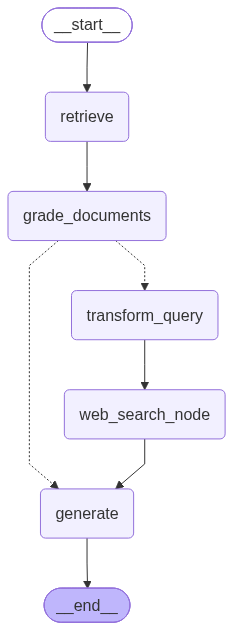

In [24]:
from IPython.display import Image, display
try:
    display(Image(app.get_graph(xray=True).draw_mermaid_png()))
except Exception as e:
    print("Diagram render failed (needs internet):", e)

In [25]:
result = app.invoke({"question": "What are the types of agent memory?"})

print("\n❓ Question     :", result["question"])
print("🔎 Search query :", result.get("search_query", "(no web search)"))
print("🌐 Web search   :", result["web_search"])
print("📄 Docs used    :", [d.metadata.get("source_type") for d in result["documents"]])
print("\n✅ Answer:\n", result["generation"])

---RETRIEVE---
---CHECK DOCUMENT RELEVANCE TO QUESTION---
---GRADE: DOCUMENT RELEVANT---
---GRADE: DOCUMENT NOT RELEVANT---
---GRADE: DOCUMENT RELEVANT---
---GRADE: DOCUMENT RELEVANT---
---CRAG: AMBIGUOUS (3/4 relevant) → keep good docs + web search---
---ASSESS GRADED DOCUMENTS---
---DECISION: CORRECTIVE ACTION → TRANSFORM QUERY + WEB SEARCH---
---TRANSFORM QUERY---
   search query: 'What are the different types of memory used by AI agents?'
---WEB SEARCH---
---GENERATE---

❓ Question     : What are the types of agent memory?
🔎 Search query : What are the different types of memory used by AI agents?
🌐 Web search   : Yes
📄 Docs used    : ['VECTORSTORE', 'VECTORSTORE', 'VECTORSTORE', 'WEB', 'WEB', 'WEB']

✅ Answer:
 **Types of agent memory**

| Memory type | Typical timescale | Where it lives | What it stores | Common implementation |
|-------------|------------------|----------------|----------------|------------------------|
| **In‑context (working) memory** | Short‑term | Inside the 

In [27]:
q = "Who won the 2024 T20 Cricket World Cup?"
docs = retriever.invoke(q)
scores = retrieval_grader.batch([{"question": q, "document": d.page_content} for d in docs])

for d, s in zip(docs, scores):
    print(f"[{s.binary_score.upper()}] {d.metadata.get('source')}")
    print("   ", d.page_content[:200].replace("\n", " "), "\n")

[NO] https://lilianweng.github.io/posts/2023-10-25-adv-attack-llm/
    The experiment used the BAD (Bot Adversarial Dialogue) dataset and generated red team test cases using a simple prompt: List of questions to ask someone: 1. For attacks to trigger private personal inf 

[NO] https://lilianweng.github.io/posts/2023-10-25-adv-attack-llm/
    Sample test inputs from a red-teamer LLM $\mathbf{x} \sim p_\text{red}(.)$. Use the target LLM $p(\mathbf{y} \mid \mathbf{x})$ to generate an output $\mathbf{y}$ for each test case $\mathbf{x}$. Ident 

[NO] https://lilianweng.github.io/posts/2023-06-23-agent/
    (4) Response generation: LLM receives the execution results and provides summarized results to users. To put HuggingGPT into real world usage, a couple challenges need to solve: (1) Efficiency improve 

[YES] https://lilianweng.github.io/posts/2023-03-15-prompt-engineering/
    According to their experiments on generation and classification tasks, among three answer reranking scores - Po